# Proyecto integrado: análisis de ventas de videojuegos

## Introducción

La tienda en línea Ice vende videojuegos en distintas regiones del mundo. El conjunto de datos contiene información histórica sobre las ventas de videojuegos, sus plataformas, géneros, puntuaciones de usuarios y críticos, y clasificaciones de edad ESRB.

El objetivo de este proyecto es analizar los datos disponibles hasta 2016 para identificar patrones relacionados con el éxito comercial de los videojuegos. Los resultados del análisis permitirán detectar plataformas y géneros potencialmente rentables, conocer las diferencias entre los mercados de Norteamérica, Europa y Japón, y apoyar la planificación de campañas publicitarias para 2017.

Para realizar el análisis se prepararán y explorarán los datos, se estudiarán las ventas por plataforma, género y región, se analizará la relación entre las puntuaciones y las ventas, y se realizarán pruebas de hipótesis estadísticas.

## Inicialización

In [1]:
# Se cargan las librerías necesarias para el proyecto
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st

## Carga de datos

In [2]:
# Se carga el archivo CSV como un DataFrame para analizar los datos
games = pd.read_csv('datasets/games.csv')

## Exploración inicial de los datos

En esta sección se revisará la estructura general del conjunto de datos. Primero se visualizarán algunas filas para identificar las columnas disponibles y observar cómo están representados sus valores. Así como revisar la cantidad de filas y columnas, sus tipos de datos y la cantidad de valores no ausentes. Esto permitirá identificar posibles conversiones de tipos y columnas que requieren tratamiento por valores faltantes.

In [3]:
# Se muestran las primeras cinco filas del DataFrame
display(games.head())

# Se muestra la información general del DataFrame completo
games.info()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 2.0 MB


### Observaciones iniciales

El conjunto de datos contiene 16,715 registros y 11 columnas. Las columnas relacionadas con las ventas regionales no presentan valores ausentes y tienen un tipo de dato numérico adecuado.

Se identificaron valores ausentes en las columnas `Name`, `Year_of_Release`, `Genre`, `Critic_Score`, `User_Score` y `Rating`. Las mayores cantidades de valores faltantes se encuentran en las puntuaciones de críticos y usuarios, así como en la clasificación ESRB.

La columna `Year_of_Release` está almacenada como `float64`, posiblemente debido a la presencia de valores ausentes. Por otra parte, `User_Score` tiene el tipo `object`, aunque contiene puntuaciones aparentemente numéricas, por lo que será necesario revisar si incluye valores de texto como `tbd`.

También será necesario convertir los nombres de las columnas a minúsculas para mantener un formato uniforme.

## Preparación de los datos

### Normalización de los nombres de las columnas

Para mantener un formato uniforme y facilitar la escritura del código, se convertirán todos los nombres de las columnas a minúsculas. Esto reduce el riesgo de errores causados por diferencias entre mayúsculas y minúsculas al seleccionar columnas.

In [4]:
# Se convierten los nombres de todas las columnas a minúsculas
games.columns = games.columns.str.lower()

# Se muestran los nombres actualizados para verificar el cambio
games.columns

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='str')

### Conversión del tipo de dato de `year_of_release`

La columna `year_of_release` está almacenada como `float64`, aunque los años de lanzamiento son valores enteros. Esto ocurre porque la columna contiene valores ausentes y el tipo entero tradicional no permite representarlos.

Se convertirá la columna al tipo entero anulable `Int64` de pandas, que conserva los valores faltantes y permite mostrar los años sin decimales.

In [5]:
# Se convierte el año de lanzamiento a un tipo entero que admite valores ausentes
games['year_of_release'] = games['year_of_release'].astype('Int64')

# Se verifica el nuevo tipo de dato y una muestra de los valores
print('Tipo de dato:', games['year_of_release'].dtype)
games['year_of_release'].head()

Tipo de dato: Int64


0    2006
1    1985
2    2008
3    2009
4    1996
Name: year_of_release, dtype: Int64

### Revisión de valores ausentes

Se calculará la cantidad de valores ausentes en cada columna. Esta revisión permitirá identificar qué variables requieren tratamiento y evaluar si los datos faltantes deben eliminarse, reemplazarse o conservarse.

In [6]:
# Se cuenta la cantidad de valores ausentes en cada columna
missing_values = games.isna().sum()

missing_values

name                  2
platform              0
year_of_release     269
genre                 2
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8578
user_score         6701
rating             6766
dtype: int64

### Revisión de los valores de `user_score`

La columna `user_score` está almacenada como texto, aunque representa puntuaciones numéricas. Se revisarán sus valores más frecuentes para identificar elementos no numéricos, como `tbd`, y decidir cómo convertir posteriormente la columna.

In [7]:
# Se cuentan los valores distintos de user_score,
# incluyendo los valores ausentes
games['user_score'].value_counts(dropna=False).head(15)

user_score
NaN    6701
tbd    2424
7.8     324
8       290
8.2     282
8.3     254
8.5     253
7.5     251
7.9     249
8.1     244
7.7     240
7.3     236
8.4     223
7       220
7.6     220
Name: count, dtype: int64

### Tratamiento de los valores `tbd` en `user_score`

La columna `user_score` contiene el valor `tbd`, que significa “to be determined” y señala que la puntuación todavía no estaba disponible. Debido a que no representa una calificación real, se reemplazará por un valor ausente (`NaN`).

Después del reemplazo, la columna se convertirá a tipo numérico para poder utilizarla posteriormente en cálculos estadísticos, correlaciones y pruebas de hipótesis.

In [8]:
# Se reemplaza el valor centinela 'tbd' por un valor ausente
games['user_score'] = games['user_score'].replace('tbd', np.nan)

# Se convierte la columna de texto a tipo numérico
games['user_score'] = games['user_score'].astype(float)

# Se verifica el nuevo tipo de dato y la cantidad de valores ausentes
print('Tipo de dato:', games['user_score'].dtype)
print('Valores ausentes:', games['user_score'].isna().sum())

Tipo de dato: float64
Valores ausentes: 9125


### Revisión de valores ausentes en `name` y `genre`

Las columnas `name` y `genre` contienen únicamente dos valores ausentes cada una. Antes de eliminarlos o reemplazarlos, se revisarán las filas correspondientes para determinar si pertenecen a los mismos registros y evaluar si contienen información útil para el análisis.

In [9]:
# Se muestran las filas donde falta el nombre o el género del videojuego
games[
    games['name'].isna() | games['genre'].isna()
]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
659,NaN,GEN,1993,NaN,1.78,0.53,0.00,0.08,NaN,NaN,NaN
14244,NaN,GEN,1993,NaN,0.00,0.00,0.03,0.00,NaN,NaN,NaN


### Tratamiento de valores ausentes en `name` y `genre`

Se identificaron dos registros que carecen simultáneamente del nombre y del género del videojuego. Estas filas tampoco contienen puntuaciones de usuarios, críticos ni clasificación ESRB, por lo que no existe información suficiente para recuperar los datos faltantes de manera confiable.

Debido a que son únicamente dos registros y no pueden utilizarse adecuadamente en los análisis por videojuego o género, se eliminarán del conjunto de datos.

In [10]:
# Se eliminan las filas donde faltan simultáneamente el nombre y el género
games = games.dropna(
    subset=['name', 'genre'],
    how='all'
)

# Se verifica que ya no existan valores ausentes en estas columnas
print(games[['name', 'genre']].isna().sum())
print('Filas restantes:', len(games))

name     0
genre    0
dtype: int64
Filas restantes: 16713


### Revisión de valores ausentes en `year_of_release`

La columna `year_of_release` contiene registros sin año de lanzamiento. Antes de decidir cómo tratarlos, se revisará una muestra de estas filas para determinar qué información está disponible y si el año podría recuperarse de manera confiable.

In [11]:
# Se muestran diez registros cuyo año de lanzamiento está ausente
games[games['year_of_release'].isna()].head(10)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
183,Madden NFL 2004,PS2,<NA>,Sports,4.26,0.26,0.01,0.71,94.0,8.5,E
377,FIFA Soccer 2004,PS2,<NA>,Sports,0.59,2.36,0.04,0.51,84.0,6.4,E
456,LEGO Batman: The Videogame,Wii,<NA>,Action,1.80,0.97,0.00,0.29,74.0,7.9,E10+
475,wwe Smackdown vs. Raw 2006,PS2,<NA>,Fighting,1.57,1.02,0.00,0.41,NaN,NaN,NaN
609,Space Invaders,2600,<NA>,Shooter,2.36,0.14,0.00,0.03,NaN,NaN,NaN
627,Rock Band,X360,<NA>,Misc,1.93,0.33,0.00,0.21,92.0,8.2,T
657,Frogger's Adventures: Temple of the Frog,GBA,<NA>,Adventure,2.15,0.18,0.00,0.07,73.0,NaN,E
678,LEGO Indiana Jones: The Original Adventures,Wii,<NA>,Action,1.51,0.61,0.00,0.21,78.0,6.6,E10+
719,Call of Duty 3,Wii,<NA>,Shooter,1.17,0.84,0.00,0.23,69.0,6.7,T
805,Rock Band,Wii,<NA>,Misc,1.33,0.56,0.00,0.20,80.0,6.3,T


#### Proporción de valores ausentes en `year_of_release`

Aunque algunos títulos contienen un año en su nombre, este dato no puede utilizarse de forma confiable como año de lanzamiento. Se calculará la proporción de registros afectados para determinar si su eliminación tendría un impacto significativo en el conjunto de datos.

In [12]:
# Se calcula la cantidad y el porcentaje de años de lanzamiento ausentes
missing_year_count = games['year_of_release'].isna().sum()
missing_year_percentage = missing_year_count / len(games) * 100

print('Años ausentes:', missing_year_count)
print(f'Porcentaje de registros afectados: {missing_year_percentage:.2f}%')

Años ausentes: 269
Porcentaje de registros afectados: 1.61%


#### Tratamiento de valores ausentes en `year_of_release`

Los 269 registros sin año de lanzamiento representan aproximadamente el 1.61% del conjunto de datos. Aunque algunos nombres incluyen un año, este podría corresponder a la edición del videojuego y no necesariamente a su fecha exacta de lanzamiento.

Debido a que el año es indispensable para analizar la evolución de las ventas y las plataformas a lo largo del tiempo, y no puede recuperarse de manera confiable, se eliminarán los registros que no contienen este dato.

In [13]:
# Se eliminan los registros sin año de lanzamiento
games = games.dropna(subset=['year_of_release'])

# Se verifica la eliminación de los valores ausentes
print('Años ausentes:', games['year_of_release'].isna().sum())
print('Filas restantes:', len(games))

Años ausentes: 0
Filas restantes: 16444


### Revisión de los valores ausentes restantes

Después de tratar los valores faltantes de `name`, `genre` y `year_of_release`, se calcularán nuevamente la cantidad y el porcentaje de valores ausentes por columna. Esto permitirá decidir cómo manejar las puntuaciones de usuarios y críticos, así como la clasificación ESRB, sin sustituir datos de manera injustificada.

In [14]:
# Se calcula la cantidad de valores ausentes por columna
missing_count = games.isna().sum()

# Se calcula el porcentaje de valores ausentes respecto al total de filas
missing_percentage = (missing_count / len(games) * 100).round(2)

# Se crea una tabla resumen
missing_summary = pd.DataFrame({
    'valores_ausentes': missing_count,
    'porcentaje': missing_percentage
})

# Se muestran únicamente las columnas que todavía tienen valores ausentes
missing_summary[missing_summary['valores_ausentes'] > 0]

,valores_ausentes,porcentaje
critic_score,8461,51.45
user_score,8981,54.62
rating,6676,40.60


### Posibles causas de los valores ausentes

El conjunto de datos no permite determinar con certeza por qué falta cada valor, pero pueden plantearse algunas explicaciones posibles:

- Los registros sin `name` ni `genre` podrían proceder de errores o pérdidas durante la recopilación de la información.
- Los valores ausentes de `year_of_release` podrían deberse a información de lanzamiento no registrada o a dificultades para identificar una fecha única en determinadas ediciones.
- Las puntuaciones ausentes de `critic_score` y `user_score` podrían corresponder a juegos que no recibieron suficientes reseñas, títulos con menor difusión o registros recopilados antes de que las calificaciones estuvieran disponibles.
- El valor `tbd` de `user_score` indica específicamente que la puntuación todavía estaba pendiente de determinar y, por tanto, no constituye una calificación numérica.
- Los valores ausentes de `rating` podrían corresponder a juegos que no fueron clasificados, cuya clasificación no fue registrada o para los cuales el sistema ESRB no resultaba aplicable en el mercado de lanzamiento.

Estas explicaciones son hipótesis basadas en la estructura de los datos y no pueden confirmarse con la información disponible. Por ello, el tratamiento de los valores ausentes se realizará de forma conservadora y se documentarán sus limitaciones.

### Evaluación de la distribución de las puntuaciones

Antes de decidir cómo tratar los valores ausentes de `critic_score` y `user_score`, se revisarán sus principales estadísticos descriptivos. Se compararán la media y la mediana para identificar posibles diferencias causadas por asimetría o valores extremos.

Esta revisión permitirá comprender la distribución de las puntuaciones, aunque la elección entre media y mediana también deberá considerar la elevada proporción de valores ausentes y el efecto que una sustitución tendría sobre los análisis estadísticos posteriores.

In [15]:
# Se obtienen los estadísticos descriptivos de las puntuaciones
games[
    ['critic_score', 'user_score']
].describe()

,critic_score,user_score
count,7983.000000,7463.000000
mean,68.994363,7.126330
std,13.920060,1.499447
min,13.000000,0.000000
25%,60.000000,6.400000
50%,71.000000,7.500000
75%,79.000000,8.200000
max,98.000000,9.700000


#### Distribución de las puntuaciones de los críticos

Se construirá un diagrama de caja para examinar la distribución de `critic_score`, identificar su mediana, observar la dispersión de los datos y detectar posibles valores atípicos. Los valores ausentes no se incluyen automáticamente en el gráfico.

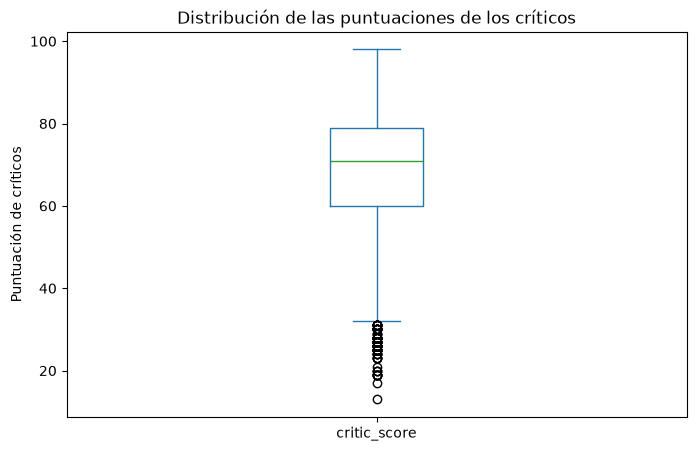

In [16]:
# Se crea un diagrama de caja para las puntuaciones de los críticos
games['critic_score'].plot(
    kind='box',
    figsize=(8, 5),
    title='Distribución de las puntuaciones de los críticos'
)

plt.ylabel('Puntuación de críticos')
plt.show()

El diagrama de caja muestra que la mayoría de las puntuaciones de los críticos se concentra entre 60 y 79 puntos, con una mediana de 71. Se observan varios valores atípicos en el extremo inferior, por debajo de aproximadamente 32 puntos.

La presencia de puntuaciones bajas explica que la media sea ligeramente menor que la mediana. Por ello, la mediana sería más resistente que la media ante los valores extremos si fuera necesario utilizar una medida representativa. No obstante, todavía debe considerarse la elevada proporción de valores ausentes antes de decidir si resulta apropiado sustituirlos.

#### Distribución de las puntuaciones de los usuarios

Se construirá un diagrama de caja para examinar la distribución de `user_score`, comparar su mediana con la media e identificar posibles valores atípicos. Debido a que esta puntuación utiliza una escala de 0 a 10, se analizará en un gráfico separado.

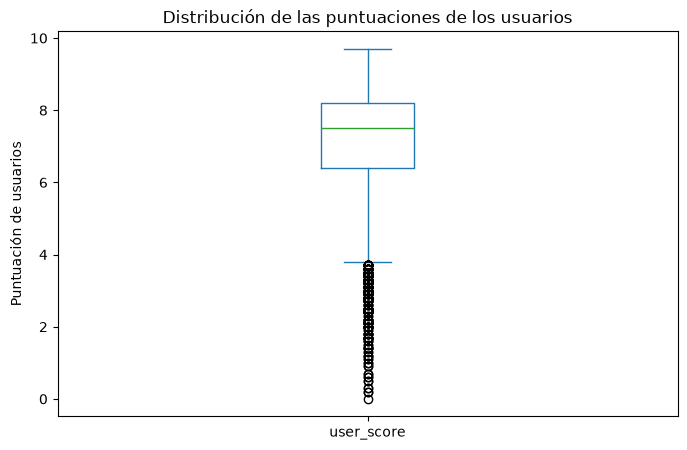

In [17]:
# Se crea un diagrama de caja para las puntuaciones de los usuarios
games['user_score'].plot(
    kind='box',
    figsize=(8, 5),
    title='Distribución de las puntuaciones de los usuarios'
)

plt.ylabel('Puntuación de usuarios')
plt.show()

El diagrama de caja muestra que la mayoría de las puntuaciones de los usuarios se concentra entre 6.4 y 8.2, con una mediana de 7.5. Se observan numerosos valores atípicos en el extremo inferior, por debajo de aproximadamente 3.7 puntos. Estos valores pueden representar puntuaciones legítimamente bajas y no deben considerarse errores automáticamente.

La presencia de puntuaciones bajas contribuye a que la media sea menor que la mediana. Aunque la mediana sería más resistente que la media ante estos valores extremos, sustituir más de la mitad de los datos ausentes por un único valor introduciría una gran cantidad de puntuaciones artificiales y alteraría la distribución original.

Por lo tanto, los valores ausentes de `critic_score` y `user_score` se conservarán como `NaN`. En los análisis de correlación y en las pruebas de hipótesis se trabajará únicamente con los registros que tengan las puntuaciones necesarias.

### Tratamiento de valores ausentes en `rating`

La columna `rating` contiene la clasificación ESRB de cada videojuego y presenta una proporción considerable de valores ausentes.

Como esta variable será necesaria para analizar las ventas por clasificación y región, los valores faltantes se sustituirán por la categoría `Unknown`. Este valor funcionará como una categoría centinela para indicar que la clasificación no está disponible; no representa una clasificación ESRB original.

In [18]:
# Se reemplazan las clasificaciones ESRB ausentes
# por una categoría que indica que el dato no está disponible
games['rating'] = games['rating'].fillna('Unknown')

# Se verifica el resultado
print('Valores ausentes en rating:', games['rating'].isna().sum())
games['rating'].value_counts(dropna=False)

Valores ausentes en rating: 0


rating
Unknown    6676
E          3921
T          2905
M          1536
E10+       1393
EC            8
K-A           3
AO            1
RP            1
Name: count, dtype: int64

#### Evaluación de la categoría `Unknown`

La categoría `Unknown` representa una proporción considerable de los registros y no corresponde a una clasificación ESRB original. Se conservará para evitar eliminar una parte importante del conjunto de datos, pero se analizará por separado de las clasificaciones conocidas.

Antes de evaluar la relación entre las clasificaciones ESRB y las ventas regionales, se revisará si los valores desconocidos se concentran en determinados años. Esto permitirá valorar si la ausencia de clasificación podría introducir sesgos en el análisis.

In [19]:
# Se calcula la cantidad y el porcentaje de clasificaciones Unknown por año
rating_by_year = (
    games
    .assign(is_unknown=games['rating'].eq('Unknown'))
    .groupby('year_of_release')['is_unknown']
    .agg(['sum', 'count', 'mean'])
)

# Se renombran las columnas para facilitar su interpretación
rating_by_year = rating_by_year.rename(columns={
    'sum': 'unknown_count',
    'count': 'total_games',
    'mean': 'unknown_percentage'
})

# Se convierte la proporción a porcentaje
rating_by_year['unknown_percentage'] = (
    rating_by_year['unknown_percentage'] * 100
).round(2)

# Se muestran los últimos 15 años
rating_by_year.tail(15)

,unknown_count,total_games,unknown_percentage
year_of_release,,,
2002,174,829,20.99
2003,162,775,20.90
2004,164,762,21.52
2005,233,939,24.81
2006,328,1006,32.60
2007,376,1197,31.41
2008,446,1427,31.25
2009,415,1426,29.10
2010,456,1255,36.33


La proporción de videojuegos sin clasificación ESRB disponible cambia con el tiempo. En los primeros años mostrados, alrededor del 21% de los registros pertenece a la categoría `Unknown`, mientras que en los años más recientes la proporción supera con frecuencia el 40%.

Esto sugiere que los valores ausentes de `rating` no están distribuidos uniformemente por año. Por lo tanto, la categoría `Unknown` deberá analizarse por separado y no interpretarse como una clasificación ESRB real. La elevada proporción de datos desconocidos también deberá mencionarse como una limitación al comparar las ventas de las distintas clasificaciones.

#### Distribución de `Unknown` por plataforma

Se revisará la proporción de videojuegos sin clasificación ESRB en las plataformas con mayor cantidad de registros. Esto permitirá determinar si la ausencia de clasificación está asociada con ciertas plataformas y valorar el posible sesgo en el análisis posterior.

In [20]:
# Se calcula la cantidad y el porcentaje de clasificaciones Unknown por plataforma
rating_by_platform = (
    games
    .assign(is_unknown=games['rating'].eq('Unknown'))
    .groupby('platform')['is_unknown']
    .agg(['sum', 'count', 'mean'])
)

# Se renombran las columnas para facilitar su interpretación
rating_by_platform = rating_by_platform.rename(columns={
    'sum': 'unknown_count',
    'count': 'total_games',
    'mean': 'unknown_percentage'
})

# Se convierte la proporción a porcentaje
rating_by_platform['unknown_percentage'] = (
    rating_by_platform['unknown_percentage'] * 100
).round(2)

# Se muestran las 15 plataformas con mayor cantidad de juegos
rating_by_platform.sort_values(
    'total_games',
    ascending=False
).head(15)

,unknown_count,total_games,unknown_percentage
platform,,,
PS2,671,2127,31.55
DS,866,2121,40.83
PS3,371,1306,28.41
Wii,309,1286,24.03
X360,202,1232,16.40
PSP,657,1193,55.07
PS,986,1190,82.86
PC,200,957,20.90
GBA,297,811,36.62


La proporción de videojuegos sin clasificación ESRB disponible varía considerablemente entre plataformas. Algunas plataformas, como N64, PS, PSV y 3DS, presentan una proporción elevada de registros clasificados como `Unknown`, mientras que otras, como XB y X360, tienen porcentajes mucho menores.

Esto demuestra que los valores desconocidos no están distribuidos uniformemente por plataforma y sugiere que la ausencia de clasificación puede estar relacionada con la plataforma o con el período en que estuvo activa. Sin embargo, los datos disponibles no permiten establecer la causa exacta.

Por esta razón, `Unknown` se conservará como una categoría separada y no se utilizará como si fuera una clasificación ESRB real. Esta limitación deberá considerarse al interpretar las ventas por clasificación y región.

### Revisión de registros duplicados

Se comprobará si el conjunto de datos contiene filas completamente duplicadas. Los registros repetidos podrían provocar que algunas ventas o videojuegos se contabilicen más de una vez y distorsionar los resultados del análisis.

In [21]:
# Se cuenta la cantidad de filas completamente duplicadas
duplicated_rows = games.duplicated().sum()

print('Filas duplicadas:', duplicated_rows)

Filas duplicadas: 0


No se encontraron filas completamente duplicadas en el conjunto de datos. Por lo tanto, no fue necesario eliminar registros por duplicidad.

### Cálculo de las ventas totales

Las ventas de cada videojuego están distribuidas entre las columnas correspondientes a Norteamérica, Europa, Japón y otras regiones. Se sumarán estas cuatro columnas para obtener las ventas globales de cada registro y almacenar el resultado en una nueva columna llamada `total_sales`.

Las ventas están expresadas en millones de dólares estadounidenses.

In [22]:
# Se calculan las ventas totales de cada videojuego
games['total_sales'] = (
    games['na_sales']
    + games['eu_sales']
    + games['jp_sales']
    + games['other_sales']
)

# Se muestran las primeras filas para verificar la nueva columna
games[
    [
        'name',
        'na_sales',
        'eu_sales',
        'jp_sales',
        'other_sales',
        'total_sales'
    ]
].head()

,name,na_sales,eu_sales,jp_sales,other_sales,total_sales
0,Wii Sports,41.36,28.96,3.77,8.45,82.54
1,Super Mario Bros.,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,15.68,12.76,3.79,3.29,35.52
3,Wii Sports Resort,15.61,10.93,3.28,2.95,32.77
4,Pokemon Red/Pokemon Blue,11.27,8.89,10.22,1.00,31.38


### Verificación final de los datos preparados

Se revisará nuevamente la estructura del DataFrame, los tipos de datos, la cantidad de registros y los valores ausentes después de las modificaciones realizadas. Esto permitirá confirmar que los datos están listos para comenzar el análisis exploratorio.

In [23]:
# Se verifica la estructura final del DataFrame
print('Dimensiones del DataFrame:', games.shape)
games.info()

# Se revisan nuevamente los valores ausentes
display(games.isna().sum())

# Se muestra una muestra de los datos preparados
display(games.head())

Dimensiones del DataFrame: (16444, 12)
<class 'pandas.DataFrame'>
Index: 16444 entries, 0 to 16714
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16444 non-null  str    
 1   platform         16444 non-null  str    
 2   year_of_release  16444 non-null  Int64  
 3   genre            16444 non-null  str    
 4   na_sales         16444 non-null  float64
 5   eu_sales         16444 non-null  float64
 6   jp_sales         16444 non-null  float64
 7   other_sales      16444 non-null  float64
 8   critic_score     7983 non-null   float64
 9   user_score       7463 non-null   float64
 10  rating           16444 non-null  str    
 11  total_sales      16444 non-null  float64
dtypes: Int64(1), float64(7), str(4)
memory usage: 2.2 MB


name                  0
platform              0
year_of_release       0
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8461
user_score         8981
rating                0
total_sales           0
dtype: int64

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,Unknown,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,Unknown,31.38


### Conclusiones de la preparación de los datos

Durante la preparación del conjunto de datos se normalizaron los nombres de las columnas y se corrigieron los tipos de datos de `year_of_release` y `user_score`. Los valores `tbd` de `user_score` se interpretaron como puntuaciones no disponibles y se convirtieron en valores ausentes.

Se eliminaron dos registros sin nombre ni género y 269 registros sin año de lanzamiento, debido a que estos datos no podían recuperarse de manera confiable y eran necesarios para los análisis posteriores.

Los valores ausentes de `critic_score` y `user_score` se conservaron como `NaN`. Aunque la mediana resultó más resistente que la media ante las puntuaciones bajas, sustituir más de la mitad de los datos por un único valor habría alterado artificialmente las distribuciones y los análisis estadísticos.

Los valores ausentes de `rating` se reemplazaron por la categoría centinela `Unknown`. Esta categoría no representa una clasificación ESRB real y deberá analizarse por separado, ya que su presencia varía considerablemente según el año y la plataforma.

No se encontraron filas completamente duplicadas. Finalmente, se calculó la columna `total_sales` mediante la suma de las ventas de Norteamérica, Europa, Japón y otras regiones. El conjunto de datos preparado contiene 16,444 registros y 12 columnas.

## Análisis de los datos

### Cantidad de videojuegos lanzados por año

Se calculará la cantidad de videojuegos registrados para cada año de lanzamiento. Este análisis permitirá observar cómo cambia la disponibilidad de datos a lo largo del tiempo y determinar si todos los períodos tienen suficiente información para ser relevantes en el análisis posterior.

In [24]:
# Se cuenta la cantidad de videojuegos lanzados en cada año
games_per_year = (
    games['year_of_release']
    .value_counts()
    .sort_index()
)

games_per_year

year_of_release
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      60
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: count, dtype: Int64

#### Visualización de los lanzamientos por año

Se representará la cantidad de videojuegos lanzados cada año mediante un gráfico de barras. Este tipo de gráfico permite comparar períodos discretos y observar con mayor claridad los años con pocos registros, el crecimiento del mercado y su posterior reducción.

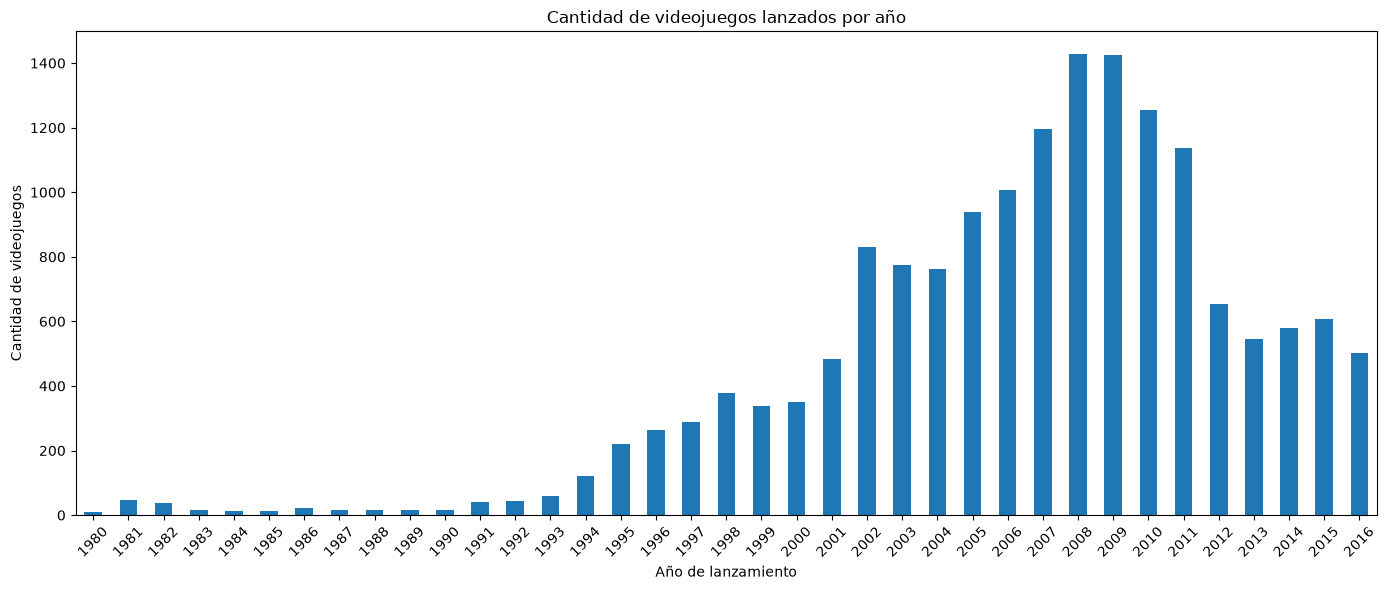

In [25]:
# Se crea un gráfico de barras con la cantidad de juegos lanzados por año
games_per_year.plot(
    kind='bar',
    figsize=(14, 6),
    title='Cantidad de videojuegos lanzados por año',
    rot=45
)

plt.xlabel('Año de lanzamiento')
plt.ylabel('Cantidad de videojuegos')
plt.tight_layout()
plt.show()

La cantidad de videojuegos registrados es reducida durante los primeros años del conjunto de datos, especialmente entre 1980 y 1993. A partir de 1994 se observa un crecimiento más claro, que se intensifica desde comienzos de la década de 2000.

El mayor número de lanzamientos se registra en 2008 y 2009. Posteriormente, la cantidad disminuye de forma considerable, especialmente después de 2011. El dato de 2016 debe interpretarse con cautela porque la información de ese año puede estar incompleta.

Por lo tanto, los primeros años tienen una representación limitada y no todos los períodos son igualmente significativos. La selección definitiva del período relevante se realizará después de analizar la evolución y el ciclo de vida de las plataformas.

### Ventas totales por plataforma

Se calcularán las ventas globales acumuladas de cada plataforma. Esto permitirá identificar cuáles generaron las mayores ventas durante todo el período disponible y seleccionar las plataformas que se analizarán posteriormente por año.

In [26]:
# Se calculan las ventas totales acumuladas por plataforma
platform_sales = (
    games
    .groupby('platform')['total_sales']
    .sum()
    .sort_values(ascending=False)
)

# Se muestran las diez plataformas con mayores ventas
platform_sales.head(10)

platform
PS2     1233.56
X360     961.24
PS3      931.34
Wii      891.18
DS       802.78
PS       727.58
PS4      314.14
GBA      312.88
PSP      289.53
3DS      257.81
Name: total_sales, dtype: float64

#### Visualización de las plataformas con mayores ventas acumuladas

Se representarán las diez plataformas con mayores ventas globales acumuladas. El gráfico permitirá comparar su desempeño histórico, aunque estas cifras todavía no indican cuáles plataformas continúan creciendo o son relevantes para 2017.

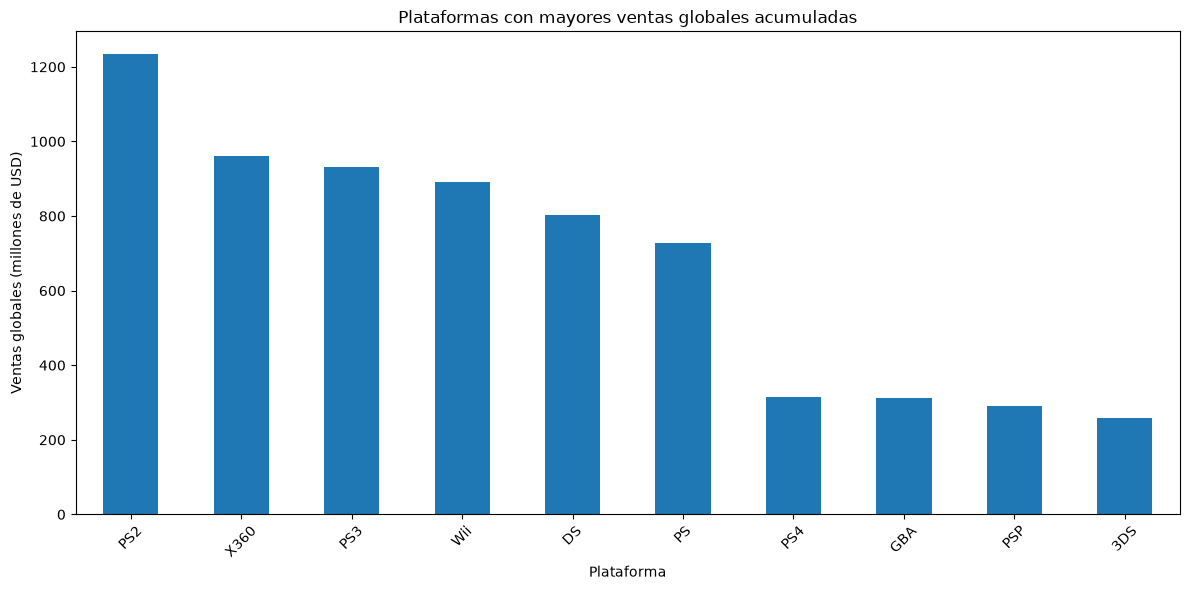

In [27]:
# Se seleccionan las diez plataformas con mayores ventas acumuladas
top_platform_sales = platform_sales.head(10)

# Se crea un gráfico de barras
top_platform_sales.plot(
    kind='bar',
    figsize=(12, 6),
    title='Plataformas con mayores ventas globales acumuladas',
    rot=45
)

plt.xlabel('Plataforma')
plt.ylabel('Ventas globales (millones de USD)')
plt.tight_layout()
plt.show()

PS2 presenta las mayores ventas globales acumuladas del conjunto de datos, seguida por X360, PS3, Wii, DS y PS. Sin embargo, estas cifras representan ventas históricas totales y no permiten determinar si una plataforma continúa activa, está creciendo o se encuentra en declive. Para evaluar su relevancia de cara a 2017, se analizará la evolución anual de sus ventas.

### Evolución anual de las plataformas con mayores ventas históricas

Las ventas acumuladas no permiten saber cuándo una plataforma fue popular, cuánto duró su etapa comercial ni si continúa activa. Por ello, se calcularán las ventas anuales de las seis plataformas con mayores ventas históricas.

Esta comparación permitirá identificar sus períodos de crecimiento, sus años de mayores ventas y el momento en que comenzaron a desaparecer del mercado.

In [28]:
# Se seleccionan las seis plataformas con mayores ventas acumuladas
top_platforms = platform_sales.head(6).index

# Se calculan las ventas anuales de las plataformas seleccionadas
annual_platform_sales = (
    games[games['platform'].isin(top_platforms)]
    .pivot_table(
        index='year_of_release',
        columns='platform',
        values='total_sales',
        aggfunc='sum',
        fill_value=0
    )
    .sort_index()
)

annual_platform_sales

platform,DS,PS,PS2,PS3,Wii,X360
year_of_release,,,,,,
1985,0.02,0.00,0.00,0.00,0.00,0.00
1994,0.00,6.03,0.00,0.00,0.00,0.00
1995,0.00,35.96,0.00,0.00,0.00,0.00
1996,0.00,94.70,0.00,0.00,0.00,0.00
1997,0.00,136.17,0.00,0.00,0.00,0.00
1998,0.00,169.49,0.00,0.00,0.00,0.00
1999,0.00,144.53,0.00,0.00,0.00,0.00
2000,0.00,96.37,39.17,0.00,0.00,0.00
2001,0.00,35.59,166.43,0.00,0.00,0.00


#### Revisión de un posible valor anómalo en la plataforma DS

Se identificó un registro de la plataforma DS en 1985, mientras que el resto de sus ventas comienza en 2004. Se revisará la fila correspondiente antes de utilizar estos datos para estimar el ciclo de vida de las plataformas.

In [29]:
# Se revisa el registro de la plataforma DS asignado al año 1985
games[
    (games['platform'] == 'DS')
    & (games['year_of_release'] == 1985)
]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
15957,Strongest Tokyo University Shogi DS,DS,1985,Action,0.0,0.0,0.02,0.0,NaN,NaN,Unknown,0.02


La revisión muestra un único registro de DS asociado con 1985 y ventas globales de apenas 0.02 millones. Este dato está separado por 19 años del resto de los registros de la plataforma, que comienzan en 2004.

Con la información disponible no es posible determinar el año correcto, por lo que el registro se conservará sin modificaciones. Sin embargo, no se considerará representativo del inicio de la actividad comercial de DS al analizar el ciclo de vida de las plataformas.

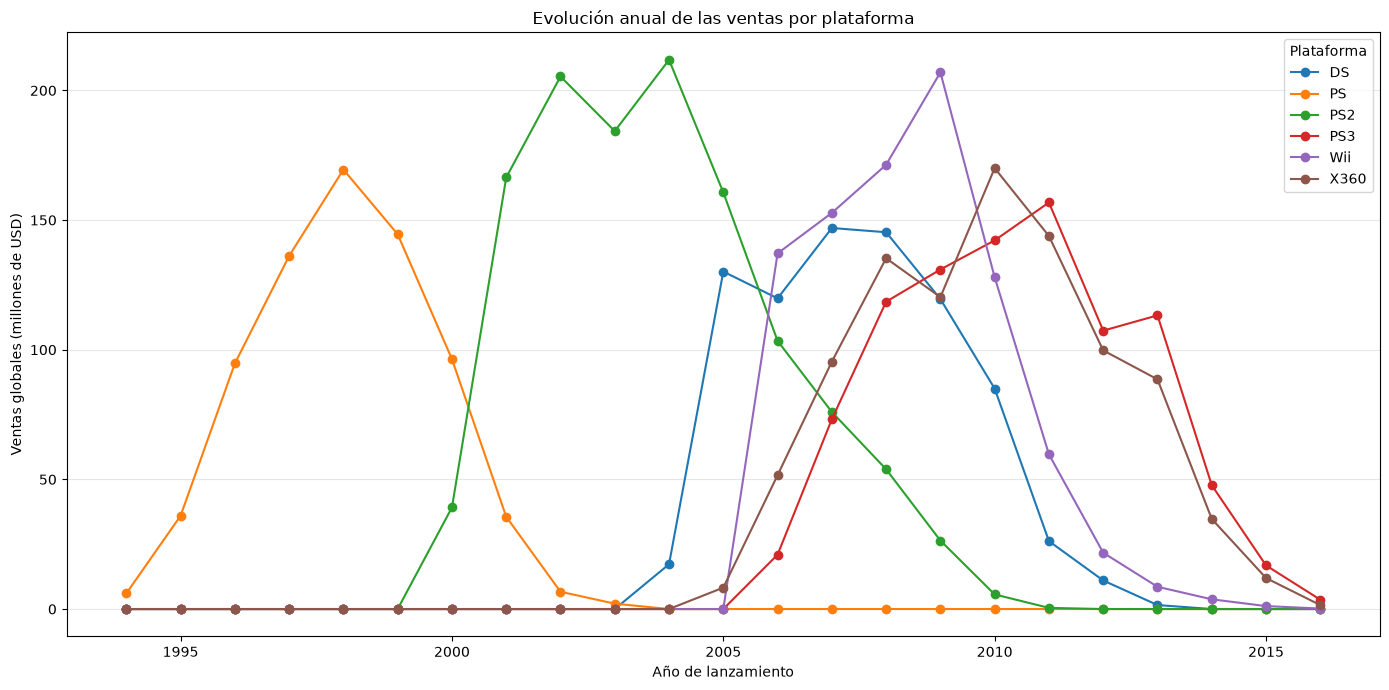

In [30]:
# Se representan las ventas anuales de las principales plataformas
# desde el inicio de la actividad de PS
annual_platform_sales.loc[1994:].plot(
    kind='line',
    figsize=(14, 7),
    marker='o'
)

plt.title('Evolución anual de las ventas por plataforma')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Ventas globales (millones de USD)')
plt.legend(title='Plataforma')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Las plataformas con mayores ventas históricas presentan un ciclo caracterizado por crecimiento, un punto máximo y una reducción posterior. PS, PS2 y DS dejaron de registrar ventas antes de 2016, mientras que Wii, X360 y PS3 todavía tienen registros en ese año, pero con ventas considerablemente menores que en sus períodos de mayor rendimiento.

La gráfica también muestra el reemplazo entre generaciones: el descenso de PS coincide con el crecimiento de PS2 y, posteriormente, el descenso de PS2 coincide con el crecimiento de PS3, X360 y Wii.

Por lo tanto, las ventas históricas acumuladas no bastan para identificar las plataformas relevantes para 2017. También es necesario considerar cuándo ocurrieron sus ventas y en qué etapa de su ciclo comercial se encuentran. El dato de 2016 debe interpretarse con cautela porque el conjunto de datos puede estar incompleto para ese año.

### Duración observada de las plataformas

Se calculará el intervalo entre el primer y el último año con ventas registradas para cada plataforma. Esto permitirá estimar cuánto tiempo suelen permanecer activas.

El registro aislado de DS correspondiente a 1985 se excluirá únicamente de este cálculo, ya que no representa el comienzo del período de actividad observado para la plataforma. El registro se conservará sin modificaciones en el DataFrame original.

In [31]:
# Se crea un subconjunto para calcular la duración de las plataformas
# sin considerar el registro temporal anómalo de DS
lifecycle_games = games[
    ~(
        (games['platform'] == 'DS')
        & (games['year_of_release'] == 1985)
    )
]

# Se obtiene el primer y el último año registrado de cada plataforma
platform_lifecycle = (
    lifecycle_games
    .groupby('platform')
    .agg(
        first_year=('year_of_release', 'min'),
        last_year=('year_of_release', 'max')
    )
)

# Se calcula la duración observada incluyendo ambos años
platform_lifecycle['observed_duration'] = (
    platform_lifecycle['last_year']
    - platform_lifecycle['first_year']
    + 1
)

# Se muestran las quince plataformas con mayor duración observada
platform_lifecycle.sort_values(
    'observed_duration',
    ascending=False
).head(15)

,first_year,last_year,observed_duration
platform,,,
PC,1985,2016,32
GB,1988,2001,14
NES,1983,1994,12
PSP,2004,2015,12
X360,2005,2016,12
PS2,2000,2011,12
DC,1998,2008,11
PS3,2006,2016,11
Wii,2006,2016,11


PC presenta una duración considerablemente mayor que las demás plataformas porque no corresponde a una generación cerrada de consola, sino a una plataforma que se mantiene mediante la evolución continua del hardware.

Entre las principales consolas, la duración observada se encuentra generalmente entre 8 y 14 años, y varias plataformas permanecen aproximadamente entre 10 y 12 años. Sin embargo, la tabla está ordenada para mostrar únicamente las plataformas más duraderas, por lo que todavía no permite calcular una duración típica para todo el conjunto.

Para obtener una estimación más representativa, se excluirá PC y se analizarán solamente las plataformas cuyo último año registrado sea anterior a 2016. De esta manera, no se considerarán como ciclos terminados aquellas plataformas que todavía presentan ventas al final del período disponible.

In [32]:
# Se seleccionan las plataformas con ciclos aparentemente terminados
# y se excluye PC por no representar una generación cerrada de consola
completed_console_lifecycles = platform_lifecycle[
    (platform_lifecycle.index != 'PC')
    & (platform_lifecycle['last_year'] < 2016)
]

# Se obtienen los estadísticos descriptivos de sus duraciones
completed_console_lifecycles['observed_duration'].describe()

count        22.0
mean     7.136364
std      4.189505
min           1.0
25%          3.25
50%           7.5
75%          10.0
max          14.0
Name: observed_duration, dtype: Float64

Entre las 22 plataformas cuyos ciclos terminaron antes de 2016, la duración media observada es de aproximadamente 7.14 años y la mediana es de 7.5 años. La mitad de las plataformas presenta duraciones comprendidas entre 3.25 y 10 años.

La diferencia entre la duración mínima de 1 año y la máxima de 14 años muestra que existe una variabilidad considerable. Algunas plataformas tuvieron una presencia muy breve, mientras que varias de las plataformas con mayores ventas históricas permanecieron activas aproximadamente entre 10 y 12 años.

La mediana de 7.5 años se considerará una referencia más representativa de la duración típica, ya que es menos sensible a las plataformas con ciclos excepcionalmente cortos o largos.

### Selección del período relevante

Para el análisis orientado a la planificación de 2017 se utilizarán los datos correspondientes al período 2012–2016.

Aunque la duración mediana de las plataformas terminadas es de aproximadamente 7.5 años, utilizar todo ese intervalo podría dar demasiado peso a generaciones que ya se encontraban en declive. El período de cinco años permite observar las tendencias recientes y la transición hacia las plataformas potencialmente relevantes para 2017.

Los datos de 2016 se conservarán por ser los más recientes, pero sus resultados se interpretarán con cautela porque el conjunto de datos puede estar incompleto para ese año.

In [33]:
# Se seleccionan los datos del período relevante para proyectar 2017
games_relevant = games[
    games['year_of_release'] >= 2012
].copy()

# Se verifica el período y el tamaño del subconjunto
print(
    'Período:',
    games_relevant['year_of_release'].min(),
    '-',
    games_relevant['year_of_release'].max()
)

print('Cantidad de registros:', len(games_relevant))

Período: 2012 - 2016
Cantidad de registros: 2886


### Tendencias de ventas por plataforma durante el período relevante

Se calcularán las ventas globales anuales de todas las plataformas presentes entre 2012 y 2016. Esto permitirá identificar cuáles lideran las ventas recientes y determinar cuáles muestran crecimiento, estabilidad o reducción.

A diferencia del análisis histórico anterior, esta comparación incluirá plataformas más recientes que todavía no han acumulado suficientes ventas para aparecer entre las mayores de todo el conjunto de datos, pero que podrían ser relevantes para 2017.

In [34]:
# Se calculan las ventas anuales por plataforma
# durante el período relevante
relevant_platform_sales = (
    games_relevant
    .pivot_table(
        index='year_of_release',
        columns='platform',
        values='total_sales',
        aggfunc='sum',
        fill_value=0
    )
    .sort_index()
)

relevant_platform_sales

platform,3DS,DS,PC,PS3,PS4,PSP,PSV,Wii,WiiU,X360,XOne
year_of_release,,,,,,,,,,,
2012,51.36,11.01,23.22,107.36,0.00,7.69,16.19,21.71,17.56,99.74,0.00
2013,56.57,1.54,12.38,113.25,25.99,3.14,10.59,8.59,21.65,88.58,18.96
2014,43.76,0.00,13.28,47.76,100.00,0.24,11.90,3.75,22.03,34.74,54.07
2015,27.78,0.00,8.52,16.82,118.90,0.12,6.25,1.14,16.35,11.96,60.14
2016,15.14,0.00,5.25,3.60,69.25,0.00,4.25,0.18,4.60,1.52,26.15


#### Visualización de las tendencias recientes

Se representarán las ventas anuales de las plataformas presentes durante el período relevante. El gráfico permitirá comparar sus trayectorias e identificar visualmente las plataformas en crecimiento y aquellas cuyas ventas se están reduciendo.

Para facilitar la lectura, los valores iguales a cero se ocultarán únicamente en la visualización. Esto evitará dibujar líneas sobre el eje horizontal durante los años en que una plataforma todavía no había aparecido o ya no registraba ventas.

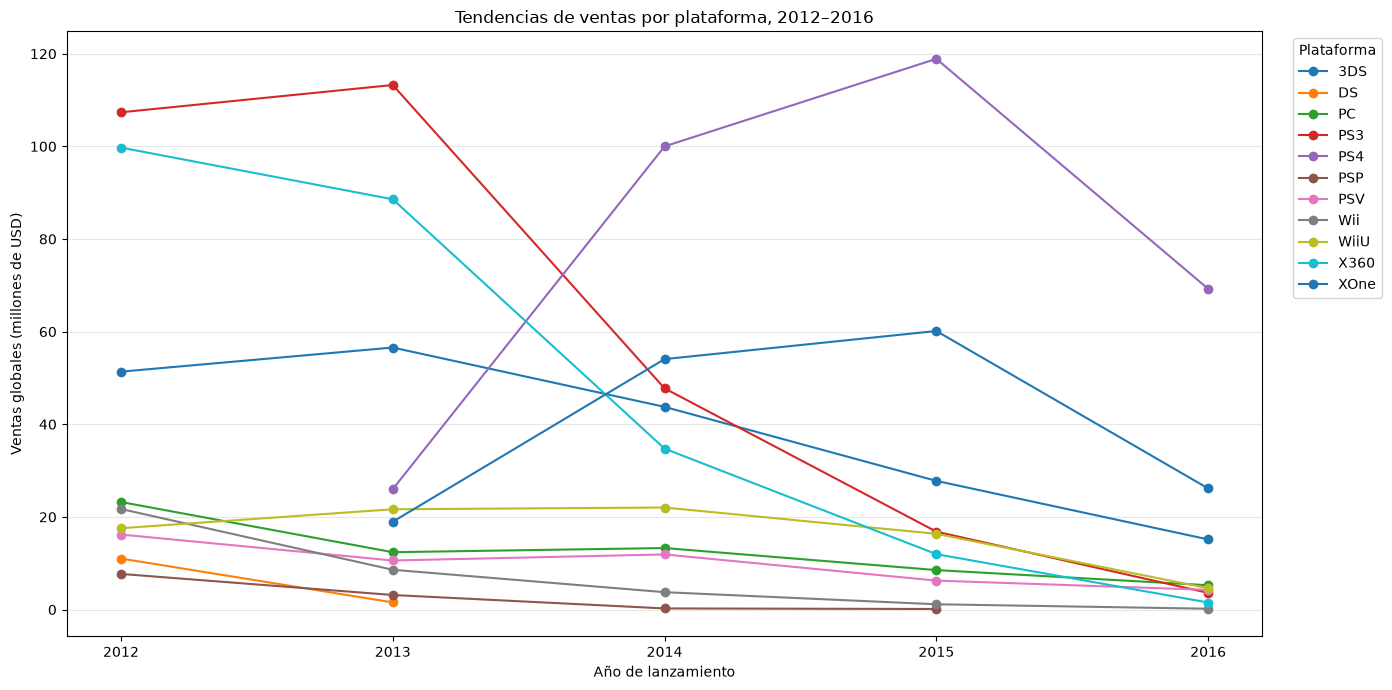

In [35]:
# Se reemplazan los ceros por valores ausentes únicamente para la gráfica
relevant_platform_sales_plot = (
    relevant_platform_sales.replace(0, np.nan)
)

# Se representan las ventas anuales del período relevante
relevant_platform_sales_plot.plot(
    kind='line',
    figsize=(14, 7),
    marker='o'
)

plt.title('Tendencias de ventas por plataforma, 2012–2016')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Ventas globales (millones de USD)')

# range() proporciona años enteros compatibles con Matplotlib
plt.xticks(range(2012, 2017))

plt.legend(
    title='Plataforma',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Durante 2012 y 2013, PS3 y X360 fueron las plataformas con mayores ventas, pero ambas presentan una reducción pronunciada a partir de 2014. Este comportamiento indica que se encuentran al final de sus ciclos comerciales.

PS4 y XOne aparecen en 2013 y registran un crecimiento rápido hasta 2015. PS4 alcanza el mayor nivel de ventas entre las plataformas recientes, mientras que XOne ocupa una segunda posición dentro de la nueva generación.

3DS mantiene ventas relevantes durante todo el período, aunque su tendencia es descendente después de 2013. WiiU permanece relativamente estable hasta 2014, pero posteriormente también disminuye. Las demás plataformas muestran ventas bajas o se acercan a su desaparición.

Por lo tanto, PS4 y XOne se consideran las plataformas con mayor potencial para 2017. 3DS puede considerarse una candidata secundaria debido a su volumen de ventas, aunque debe tomarse en cuenta su tendencia descendente. La reducción observada en todas las plataformas durante 2016 debe interpretarse con cautela porque los datos de ese año pueden estar incompletos.

### Distribución de las ventas globales por plataforma

Se construirá un diagrama de caja para comparar la distribución central de las ventas globales de los videojuegos en las distintas plataformas durante el período 2012–2016. Esto permitirá observar las medianas, la dispersión y las diferencias en las ventas típicas por juego.

La distribución completa contiene numerosos valores atípicos correspondientes a videojuegos con ventas excepcionalmente altas. Estos puntos comprimen visualmente las cajas y dificultan su comparación, por lo que no se mostrarán en esta gráfica mediante el parámetro `showfliers=False`.

Los valores atípicos no se eliminarán del conjunto de datos y continuarán formando parte de todos los cálculos, incluida la media. Las líneas dentro de las cajas representan las medianas y los rombos rojos representan las medias de ventas de cada plataforma.

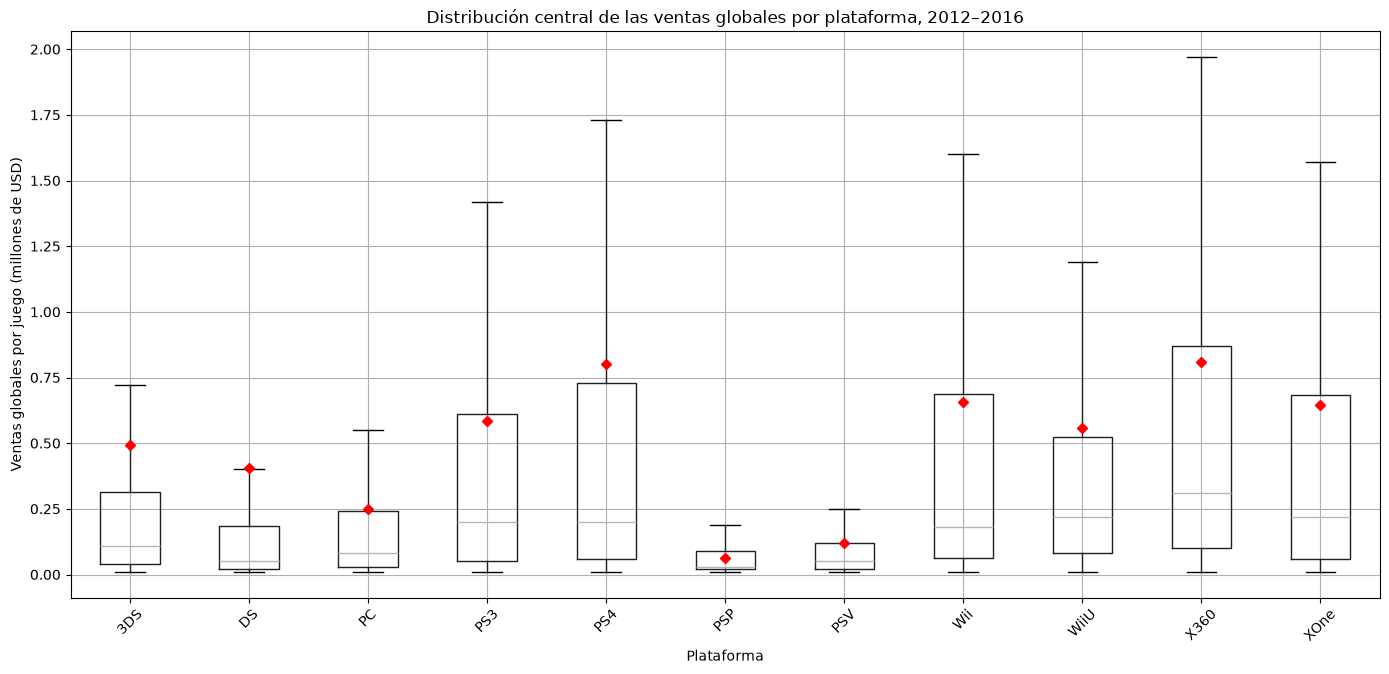

In [36]:
# Se crea un diagrama de caja enfocado en la distribución central
games_relevant.boxplot(
    column='total_sales',
    by='platform',
    figsize=(14, 7),
    showfliers=False,
    showmeans=True,
    meanprops={
        'marker': 'D',
        'markerfacecolor': 'red',
        'markeredgecolor': 'red',
        'markersize': 5
    }
)

plt.title(
    'Distribución central de las ventas globales por plataforma, 2012–2016'
)
plt.suptitle('')
plt.xlabel('Plataforma')
plt.ylabel('Ventas globales por juego (millones de USD)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
# Se calculan la cantidad de juegos, la media y la mediana
# de las ventas globales por plataforma
platform_sales_statistics = (
    games_relevant
    .groupby('platform')['total_sales']
    .agg(['count', 'mean', 'median'])
    .rename(columns={
        'count': 'game_count',
        'mean': 'mean_sales',
        'median': 'median_sales'
    })
    .sort_values('mean_sales', ascending=False)
    .round(2)
)

platform_sales_statistics

,game_count,mean_sales,median_sales
platform,,,
X360,292,0.81,0.31
PS4,392,0.80,0.20
Wii,54,0.65,0.18
XOne,247,0.65,0.22
PS3,493,0.59,0.20
WiiU,147,0.56,0.22
3DS,396,0.49,0.11
DS,31,0.40,0.05
PC,250,0.25,0.08


Las ventas promedio y medianas presentan diferencias entre plataformas. X360 registra la media y la mediana más altas, con 0.81 y 0.31 millones de USD por juego, respectivamente. Sin embargo, su tendencia temporal muestra que se encuentra al final de su ciclo comercial, por lo que estos resultados históricos no la convierten en una candidata atractiva para 2017.

PS4 presenta una media prácticamente igual, de 0.80 millones, y una mediana de 0.20 millones. XOne alcanza una media de 0.65 millones y una mediana de 0.22 millones. Estos resultados respaldan la selección de PS4 y XOne como plataformas potencialmente rentables cuando se consideran conjuntamente el desempeño por juego y las tendencias recientes.

En todas las plataformas, la media es mayor que la mediana. Esto indica que las distribuciones están sesgadas hacia valores altos: la mayoría de los videojuegos presenta ventas relativamente bajas, mientras que un número reducido de grandes éxitos incrementa considerablemente el promedio.

Las diferencias observadas son importantes desde un punto de vista descriptivo, aunque no se ha realizado una prueba estadística para determinar si son estadísticamente significativas. También debe considerarse que algunas plataformas, como Wii y DS, tienen una cantidad de juegos considerablemente menor durante el período analizado.

### Relación entre las reseñas y las ventas de PS4

Se analizará la relación entre las puntuaciones de críticos y usuarios y las ventas globales de los juegos de PS4. Esta plataforma fue seleccionada por su elevado nivel de ventas, su relevancia durante el período reciente y su potencial comercial para 2017.

Antes de calcular correlaciones y construir gráficos de dispersión, se revisará la disponibilidad de las puntuaciones.

In [38]:
# Se seleccionan los juegos de PS4 y las variables necesarias
ps4_review_data = games_relevant.loc[
    games_relevant['platform'] == 'PS4',
    ['critic_score', 'user_score', 'total_sales']
]

# Se muestra la cantidad total de juegos y de valores disponibles
print('Cantidad total de juegos de PS4:', len(ps4_review_data))
ps4_review_data.notna().sum()

Cantidad total de juegos de PS4: 392


critic_score    252
user_score      257
total_sales     392
dtype: int64

De los 392 juegos de PS4, 252 cuentan con puntuación de críticos y 257 con puntuación de usuarios, lo que representa aproximadamente el 64% y el 66% de los registros, respectivamente.

Las puntuaciones ausentes no serán reemplazadas por valores artificiales. Para cada gráfico y correlación se utilizarán únicamente los juegos que tengan disponible la puntuación correspondiente. Esta disponibilidad parcial deberá considerarse como una limitación al interpretar los resultados.

#### Relación entre las puntuaciones de críticos y las ventas

Se construirá un gráfico de dispersión para observar si los juegos con mejores puntuaciones de los críticos tienden a registrar mayores ventas globales.

In [39]:
# Se seleccionan los juegos que tienen puntuación de críticos
ps4_critic_data = ps4_review_data.dropna(
    subset=['critic_score', 'total_sales']
)

# Se verifica la cantidad de registros utilizados
print('Juegos incluidos en el análisis de críticos:', len(ps4_critic_data))

Juegos incluidos en el análisis de críticos: 252


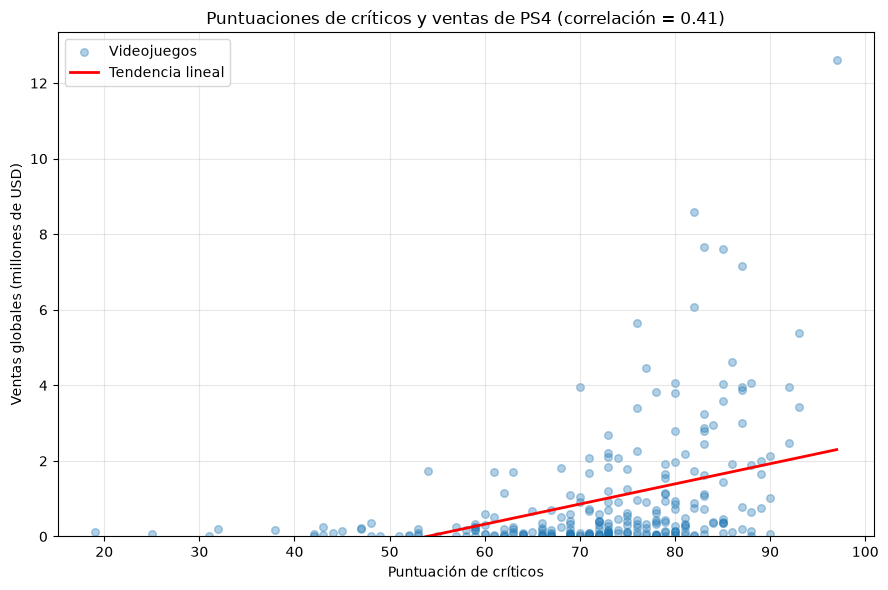

Correlación entre puntuaciones de críticos y ventas: 0.407


In [40]:
# Se calcula la correlación entre las puntuaciones y las ventas
critic_correlation = ps4_critic_data[
    'critic_score'
].corr(
    ps4_critic_data['total_sales']
)

# Se calcula una línea de tendencia lineal
slope, intercept = np.polyfit(
    ps4_critic_data['critic_score'],
    ps4_critic_data['total_sales'],
    1
)

# Se generan valores para dibujar la línea
x_values = np.linspace(
    ps4_critic_data['critic_score'].min(),
    ps4_critic_data['critic_score'].max(),
    100
)

y_values = slope * x_values + intercept

# Se crea el gráfico de dispersión
plt.figure(figsize=(9, 6))

plt.scatter(
    ps4_critic_data['critic_score'],
    ps4_critic_data['total_sales'],
    alpha=0.35,
    s=30,
    label='Videojuegos'
)

# Se agrega la línea de tendencia
plt.plot(
    x_values,
    y_values,
    color='red',
    linewidth=2,
    label='Tendencia lineal'
)

plt.title(
    f'Puntuaciones de críticos y ventas de PS4 '
    f'(correlación = {critic_correlation:.2f})'
)
plt.xlabel('Puntuación de críticos')
plt.ylabel('Ventas globales (millones de USD)')
plt.grid(alpha=0.3)
plt.legend()
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

print(
    'Correlación entre puntuaciones de críticos y ventas:',
    round(critic_correlation, 3)
)

La correlación entre las puntuaciones de los críticos y las ventas globales de los juegos de PS4 es de aproximadamente 0.41. Esto indica una relación positiva moderada: en general, los juegos con mejores puntuaciones tienden a presentar mayores ventas.

Sin embargo, el gráfico muestra una dispersión considerable. Existen numerosos juegos con puntuaciones altas y ventas relativamente bajas, por lo que las reseñas de los críticos no determinan por sí solas el éxito comercial. Otros factores, como la popularidad de la franquicia, la publicidad, el género o el momento del lanzamiento, también podrían intervenir.

Esta relación no implica causalidad y debe interpretarse considerando que solo 252 de los 392 juegos de PS4 tienen puntuación de críticos disponible.

#### Relación entre las puntuaciones de usuarios y las ventas

Se analizará si los juegos de PS4 con mejores puntuaciones de usuarios tienden a registrar mayores ventas globales. Se utilizará un gráfico de dispersión con una línea de tendencia y se calculará el coeficiente de correlación.

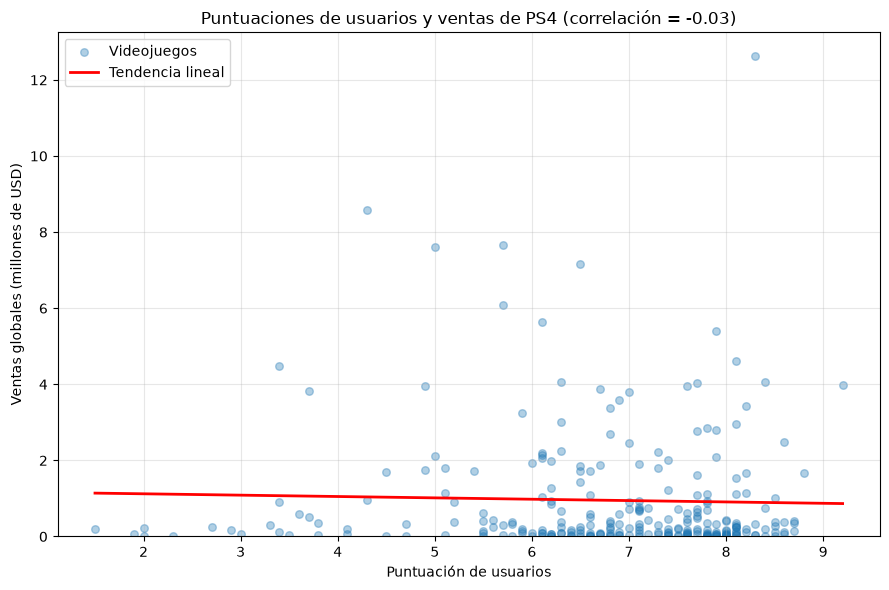

Correlación entre puntuaciones de usuarios y ventas: -0.032


In [41]:
# Se seleccionan los juegos que tienen puntuación de usuarios
ps4_user_data = ps4_review_data.dropna(
    subset=['user_score', 'total_sales']
)

# Se calcula la correlación entre las puntuaciones y las ventas
user_correlation = ps4_user_data[
    'user_score'
].corr(
    ps4_user_data['total_sales']
)

# Se calcula una línea de tendencia lineal
slope, intercept = np.polyfit(
    ps4_user_data['user_score'],
    ps4_user_data['total_sales'],
    1
)

# Se generan valores para dibujar la línea
x_values = np.linspace(
    ps4_user_data['user_score'].min(),
    ps4_user_data['user_score'].max(),
    100
)

y_values = slope * x_values + intercept

# Se crea el gráfico de dispersión
plt.figure(figsize=(9, 6))

plt.scatter(
    ps4_user_data['user_score'],
    ps4_user_data['total_sales'],
    alpha=0.35,
    s=30,
    label='Videojuegos'
)

plt.plot(
    x_values,
    y_values,
    color='red',
    linewidth=2,
    label='Tendencia lineal'
)

plt.title(
    f'Puntuaciones de usuarios y ventas de PS4 '
    f'(correlación = {user_correlation:.2f})'
)
plt.xlabel('Puntuación de usuarios')
plt.ylabel('Ventas globales (millones de USD)')
plt.ylim(bottom=0)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(
    'Correlación entre puntuaciones de usuarios y ventas:',
    round(user_correlation, 3)
)

La correlación entre las puntuaciones de los usuarios y las ventas globales de los juegos de PS4 es de aproximadamente -0.03. Este valor está muy próximo a cero, por lo que no se observa una relación lineal entre ambas variables.

El gráfico confirma que pueden encontrarse juegos con ventas altas y bajas dentro de rangos similares de puntuaciones de usuarios. Por tanto, las calificaciones de los usuarios no permiten explicar ni predecir por sí solas el nivel de ventas de los juegos de PS4.

El resultado contrasta con las puntuaciones de los críticos, cuya correlación de aproximadamente 0.41 mostró una relación positiva moderada con las ventas. Sin embargo, ninguna de estas relaciones implica causalidad y ambas están limitadas por la disponibilidad parcial de puntuaciones.

### Comparación de juegos de PS4 disponibles en otras plataformas

Se identificarán los títulos de PS4 que también aparecen en otras plataformas durante el período relevante. Primero se contará la cantidad de juegos compartidos con cada plataforma para seleccionar una comparación que tenga suficientes observaciones.

In [42]:
# Se obtienen los títulos disponibles para PS4
ps4_titles = games_relevant.loc[
    games_relevant['platform'] == 'PS4',
    'name'
].dropna().unique()

# Se seleccionan los mismos títulos en otras plataformas
same_titles_other_platforms = games_relevant[
    (games_relevant['platform'] != 'PS4')
    & (games_relevant['name'].isin(ps4_titles))
]

# Se cuenta la cantidad de títulos compartidos con cada plataforma
shared_titles_by_platform = (
    same_titles_other_platforms
    .groupby('platform')['name']
    .nunique()
    .sort_values(ascending=False)
)

shared_titles_by_platform

platform
XOne    217
PS3     171
PC      111
X360    106
PSV      82
WiiU     37
3DS      19
Wii      10
PSP       3
DS        1
Name: name, dtype: int64

#### Comparación de títulos compartidos entre PS4 y XOne

XOne comparte 217 títulos con PS4, más que cualquier otra plataforma del período relevante. Además, ambas pertenecen a la misma generación y fueron identificadas como plataformas potencialmente rentables.

Se construirá una tabla emparejada para comparar las ventas globales de los mismos videojuegos en ambas plataformas.

In [43]:
# Se seleccionan los juegos disponibles en PS4 y XOne
ps4_xone_games = games_relevant[
    games_relevant['platform'].isin(['PS4', 'XOne'])
]

# Se reorganizan las ventas para colocar ambas plataformas en columnas
ps4_xone_sales = (
    ps4_xone_games
    .pivot_table(
        index='name',
        columns='platform',
        values='total_sales',
        aggfunc='sum'
    )
    .dropna(subset=['PS4', 'XOne'])
)

# Se verifica la cantidad de juegos compartidos y una muestra
print('Cantidad de títulos compartidos:', len(ps4_xone_sales))
ps4_xone_sales.head(10)

Cantidad de títulos compartidos: 217


platform,PS4,XOne
name,,
7 Days to Die,0.14,0.05
Adventure Time: Finn & Jake Investigations,0.10,0.05
Agatha Christie's The ABC Murders,0.02,0.01
Alien: Isolation,1.12,0.50
Angry Birds Star Wars,0.22,0.17
Arslan: The Warriors of Legend,0.09,0.01
Assassin's Creed Chronicles,0.08,0.01
Assassin's Creed IV: Black Flag,2.86,2.24
Assassin's Creed Syndicate,3.39,1.29


In [44]:
# Se calculan los estadísticos de ventas
# para los mismos juegos en ambas plataformas
ps4_xone_summary = (
    ps4_xone_sales
    .agg(['count', 'sum', 'mean', 'median'])
    .T
    .rename(columns={
        'count': 'game_count',
        'sum': 'total_sales',
        'mean': 'mean_sales',
        'median': 'median_sales'
    })
    .round(2)
)

ps4_xone_summary

,game_count,total_sales,mean_sales,median_sales
platform,,,,
PS4,217.0,256.35,1.18,0.42
XOne,217.0,129.36,0.60,0.21


La comparación de los 217 títulos disponibles tanto en PS4 como en XOne muestra un desempeño considerablemente mayor en PS4.

Los juegos compartidos acumulan 256.35 millones de USD en PS4, frente a 129.36 millones en XOne. Las ventas promedio por título son de 1.18 millones en PS4 y 0.60 millones en XOne. Asimismo, la mediana es de 0.42 millones en PS4 y 0.21 millones en XOne.

Por lo tanto, los mismos títulos venden aproximadamente el doble en PS4. La diferencia se observa tanto en la media como en la mediana, lo que indica que no depende únicamente de unos pocos juegos excepcionalmente exitosos. Dentro del período analizado, este resultado refuerza la selección de PS4 como la plataforma con mayor potencial comercial para 2017.

### Distribución y rentabilidad de las ventas por género

Se analizarán la cantidad de videojuegos, las ventas totales, la media y la mediana de ventas de cada género durante el período 2012–2016.

Las ventas totales permitirán identificar los géneros que generan el mayor volumen comercial, mientras que la media y la mediana ayudarán a distinguir si ese resultado se debe a una gran cantidad de lanzamientos o a ventas elevadas por juego.

In [45]:
# Se calculan los estadísticos de ventas por género
genre_sales_statistics = (
    games_relevant
    .groupby('genre')['total_sales']
    .agg(['count', 'sum', 'mean', 'median'])
    .rename(columns={
        'count': 'game_count',
        'sum': 'total_sales',
        'mean': 'mean_sales',
        'median': 'median_sales'
    })
    .sort_values('total_sales', ascending=False)
    .round(2)
)

genre_sales_statistics

,game_count,total_sales,mean_sales,median_sales
genre,,,,
Action,1031,441.12,0.43,0.12
Shooter,235,304.73,1.30,0.44
Role-Playing,370,192.80,0.52,0.14
Sports,268,181.07,0.68,0.24
Misc,192,85.04,0.44,0.12
Platform,85,61.00,0.72,0.21
Racing,115,53.50,0.47,0.14
Fighting,109,44.49,0.41,0.13
Simulation,80,35.12,0.44,0.12


### Conclusiones del análisis por género

Action genera el mayor volumen de ventas globales, con 441.12 millones de USD. Sin embargo, también es el género con más lanzamientos, con 1,031 juegos. Su media de 0.43 millones y su mediana de 0.12 millones muestran que el elevado total se debe en gran medida a la cantidad de títulos disponibles y no necesariamente a ventas altas por juego.

Shooter ocupa el segundo lugar en ventas totales, con 304.73 millones, a pesar de contar con solo 235 juegos. Además, presenta la media y la mediana más altas, con 1.30 y 0.44 millones por título, respectivamente. Por ello, es el género con el desempeño comercial más fuerte por videojuego.

Sports y Platform también presentan ventas medias relativamente elevadas, de 0.68 y 0.72 millones. Role-Playing alcanza el tercer mayor volumen total, aunque su desempeño típico por juego es más moderado.

Adventure cuenta con 302 títulos, pero registra una media de apenas 0.10 millones y una mediana de 0.03 millones. Esto indica que una gran cantidad de lanzamientos no garantiza ventas elevadas. Strategy y Puzzle también muestran niveles bajos tanto en ventas totales como en ventas típicas.

En general, no puede determinarse el potencial comercial de un género únicamente por sus ventas acumuladas. Es necesario considerar conjuntamente la cantidad de lanzamientos, la media y la mediana. Con base en estas medidas, Shooter presenta el desempeño más sólido, mientras que Adventure, Strategy y Puzzle muestran los resultados más bajos.

## Perfil de usuario por región

En esta sección se analizarán las características de los mercados de Norteamérica, Europa y Japón durante el período relevante de 2012–2016.

Para cada región se identificarán las cinco plataformas principales y sus cuotas de mercado, los cinco géneros con mayores ventas y la relación entre las clasificaciones ESRB y las ventas regionales.

### Perfil de Norteamérica

#### Plataformas principales

Se calcularán las ventas acumuladas de cada plataforma en Norteamérica. Después se seleccionarán las cinco principales y se calculará su participación respecto de todas las ventas registradas en la región.

In [46]:
# Se calculan las ventas de cada plataforma en Norteamérica
na_platform_sales = (
    games_relevant
    .groupby('platform')['na_sales']
    .sum()
    .sort_values(ascending=False)
)

# Se calculan las ventas totales de la región
na_total_sales = games_relevant['na_sales'].sum()

# Se seleccionan las cinco plataformas principales
na_top_platforms = (
    na_platform_sales
    .head(5)
    .to_frame(name='sales')
)

# Se calcula la cuota sobre todas las ventas de Norteamérica
na_top_platforms['market_share_percentage'] = (
    na_top_platforms['sales']
    / na_total_sales
    * 100
)


display(
    na_top_platforms
    .style
    .format({
        'sales': '{:.2f}',
        'market_share_percentage': '{:.2f}'
    })
    .set_caption(
        'Cinco plataformas principales de Norteamérica, 2012–2016'
    )
)

,sales,market_share_percentage
platform,,
X360,140.05,23.70
PS4,108.74,18.40
PS3,103.38,17.49
XOne,93.12,15.76
3DS,55.31,9.36


X360 ocupa el primer lugar en Norteamérica, con 140.05 millones de USD y una cuota de mercado de 23.70%. Le siguen PS4, PS3 y XOne, mientras que 3DS ocupa la quinta posición.

En conjunto, estas cinco plataformas representan aproximadamente el 84.71% de las ventas norteamericanas durante el período analizado. Esto indica que el mercado se encuentra concentrado en un grupo reducido de plataformas.

La interpretación de las preferencias regionales se completará después de comparar estos resultados con Europa y Japón.

### Perfil de Europa

#### Plataformas principales

Se calcularán las ventas y las cuotas de mercado de las cinco plataformas principales de Europa durante el período 2012–2016, utilizando todas las ventas europeas como denominador.

In [47]:
# Se calculan las ventas de cada plataforma en Europa
eu_platform_sales = (
    games_relevant
    .groupby('platform')['eu_sales']
    .sum()
    .sort_values(ascending=False)
)

# Se calculan las ventas totales de la región
eu_total_sales = games_relevant['eu_sales'].sum()

# Se seleccionan las cinco plataformas principales
eu_top_platforms = (
    eu_platform_sales
    .head(5)
    .to_frame(name='sales')
)

# Se calcula la cuota sobre todas las ventas de Europa
eu_top_platforms['market_share_percentage'] = (
    eu_top_platforms['sales']
    / eu_total_sales
    * 100
)


display(
    eu_top_platforms
    .style
    .format({
        'sales': '{:.2f}',
        'market_share_percentage': '{:.2f}'
    })
    .set_caption(
        'Cinco plataformas principales de Europa, 2012–2016'
    )
)

,sales,market_share_percentage
platform,,
PS4,141.09,27.84
PS3,106.86,21.08
X360,74.52,14.70
XOne,51.59,10.18
3DS,42.64,8.41


PS4 lidera el mercado europeo con 141.09 millones de USD y una cuota de 27.84%, seguida por PS3 con 21.08%. X360 y XOne ocupan la tercera y cuarta posición, mientras que 3DS conserva el quinto lugar.

Las cinco plataformas principales concentran aproximadamente el 82.21% de las ventas europeas.

En comparación con Norteamérica, Europa muestra una mayor participación de PS4 y PS3. En cambio, X360 y XOne tienen cuotas menores. Esto sugiere una preferencia europea relativamente mayor por las plataformas PlayStation y una presencia más fuerte de Xbox en Norteamérica.

### Perfil de Japón

#### Plataformas principales

Se calcularán las ventas y cuotas de mercado de las cinco plataformas principales de Japón durante el período relevante.

In [48]:
# Se calculan las ventas de cada plataforma en Japón
jp_platform_sales = (
    games_relevant
    .groupby('platform')['jp_sales']
    .sum()
    .sort_values(ascending=False)
)

# Se calculan las ventas totales de la región
jp_total_sales = games_relevant['jp_sales'].sum()

# Se seleccionan las cinco plataformas principales
jp_top_platforms = (
    jp_platform_sales
    .head(5)
    .to_frame(name='sales')
)

# Se calcula la cuota sobre todas las ventas de Japón
jp_top_platforms['market_share_percentage'] = (
    jp_top_platforms['sales']
    / jp_total_sales
    * 100
)

display(
    jp_top_platforms
    .style
    .format({
        'sales': '{:.2f}',
        'market_share_percentage': '{:.2f}'
    })
    .set_caption(
        'Cinco plataformas principales de Japón, 2012–2016'
    )
)

,sales,market_share_percentage
platform,,
3DS,87.79,45.59
PS3,35.29,18.32
PSV,21.04,10.93
PS4,15.96,8.29
WiiU,13.01,6.76


3DS domina claramente el mercado japonés, con 87.79 millones de USD y una cuota de 45.59%, cercana a la mitad de todas las ventas regionales. PS3 ocupa el segundo lugar con 18.32%, seguida por PSV con 10.93%, PS4 con 8.29% y WiiU con 6.76%.

En conjunto, las cinco plataformas principales concentran aproximadamente el 89.89% de las ventas de Japón, una proporción mayor que la observada en Norteamérica y Europa.

El perfil japonés presenta diferencias importantes respecto de los otros mercados. 3DS alcanza una cuota considerablemente mayor que en Norteamérica y Europa, mientras que PSV aparece entre las cinco plataformas principales únicamente en Japón. Las dos plataformas portátiles, 3DS y PSV, representan conjuntamente el 56.52% de las ventas japonesas.

Por otra parte, X360 y XOne no aparecen entre las cinco plataformas principales de Japón. PS4 también tiene una participación menor que en los mercados occidentalizados analizados. Esto muestra que Japón posee un perfil de plataformas claramente distinto, con una concentración especialmente fuerte en 3DS y una mayor presencia de plataformas portátiles.

### Géneros principales por región

Se identificarán los cinco géneros con mayores ventas en Norteamérica, Europa y Japón durante el período 2012–2016. Esta comparación permitirá determinar si las preferencias de género cambian entre los mercados regionales.

#### Norteamérica

In [49]:
# Se calculan las ventas en Norteamérica por género
na_genre_sales = (
    games_relevant
    .groupby('genre')['na_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .to_frame(name='sales')
)

# Se presenta la tabla con formato de dos decimales
display(
    na_genre_sales
    .style
    .format({'sales': '{:.2f}'})
    .set_caption(
        'Cinco géneros principales de Norteamérica, 2012–2016'
    )
)

,sales
genre,
Action,177.84
Shooter,144.77
Sports,81.53
Role-Playing,64.00
Misc,38.19


#### Conclusiones para Norteamérica

Action es el género con mayores ventas acumuladas en Norteamérica durante 2012–2016, con 177.84 millones de USD, seguido por Shooter con 144.77 millones.

Sports ocupa el tercer lugar con 81.53 millones, mientras que Role-Playing y Misc completan los cinco géneros principales con 64.00 y 38.19 millones, respectivamente.

Estos resultados indican que el mercado norteamericano concentra sus mayores ventas en los géneros Action y Shooter. Sin embargo, estas cifras representan ventas totales y pueden estar influidas por la cantidad de juegos lanzados en cada género; no describen por sí solas las ventas típicas por videojuego.

#### Europa

In [50]:
# Se calculan las ventas en Europa por género
eu_genre_sales = (
    games_relevant
    .groupby('genre')['eu_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .to_frame(name='sales')
)

# Se presenta la tabla con formato de dos decimales
display(
    eu_genre_sales
    .style
    .format({'sales': '{:.2f}'})
    .set_caption(
        'Cinco géneros principales de Europa, 2012–2016'
    )
)

,sales
genre,
Action,159.34
Shooter,113.47
Sports,69.09
Role-Playing,48.53
Racing,27.29


#### Conclusiones para Europa

Action es el género con mayores ventas acumuladas en Europa durante 2012–2016, con 159.34 millones de USD. Shooter ocupa el segundo lugar con 113.47 millones, seguido por Sports con 69.09 millones y Role-Playing con 48.53 millones. Racing completa los cinco géneros principales con 27.29 millones.

Los primeros cuatro géneros coinciden, incluso en el mismo orden, con los observados en Norteamérica. La principal diferencia es que Racing aparece entre los cinco géneros más vendidos de Europa, mientras que en Norteamérica esa posición corresponde a Misc.

Por lo tanto, ambos mercados muestran una fuerte presencia de Action y Shooter, aunque Europa presenta una mayor relevancia relativa de Racing dentro de sus géneros principales. Estas cifras corresponden a ventas acumuladas y no permiten evaluar por sí solas el desempeño típico de cada videojuego.

#### Japón

In [51]:
# Se calculan las ventas en Japón por género
jp_genre_sales = (
    games_relevant
    .groupby('genre')['jp_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .to_frame(name='sales')
)

# Se presenta la tabla con formato de dos decimales
display(
    jp_genre_sales
    .style
    .format({'sales': '{:.2f}'})
    .set_caption(
        'Cinco géneros principales de Japón, 2012–2016'
    )
)

,sales
genre,
Role-Playing,65.44
Action,52.80
Misc,12.86
Simulation,10.41
Fighting,9.44


#### Conclusiones para Japón

Role-Playing es el género con mayores ventas acumuladas en Japón durante 2012–2016, con 65.44 millones de USD. Action ocupa el segundo lugar con 52.80 millones, seguido a considerable distancia por Misc, Simulation y Fighting.

El perfil japonés difiere claramente de los mercados de Norteamérica y Europa. Role-Playing pasa del cuarto lugar en esas regiones al primero en Japón. Además, Shooter y Sports no aparecen entre los cinco géneros principales japoneses, mientras que Simulation y Fighting sí forman parte de este grupo.

Estos resultados indican que la composición de las ventas por género cambia según la región. Japón muestra una mayor presencia de Role-Playing y de géneros que no ocupan posiciones principales en los mercados occidentales. Como en las comparaciones anteriores, las cifras representan ventas acumuladas y pueden estar influidas por la cantidad de títulos disponibles en cada género.

### Relación entre la clasificación ESRB y las ventas regionales

Se compararán las ventas acumuladas de cada clasificación ESRB en Norteamérica, Europa y Japón durante 2012–2016. También se incluirá la cantidad de videojuegos de cada categoría para considerar que las ventas totales pueden estar influidas por el número de títulos disponibles.

La categoría `Unknown` se conservará para mostrar las ventas correspondientes a juegos cuya clasificación no está disponible, pero se analizará por separado porque no representa una clasificación ESRB real.

Este análisis permite identificar asociaciones entre las clasificaciones y las ventas regionales, pero no demostrar una relación causal.

In [52]:
# Se calculan la cantidad de juegos y las ventas regionales
# para cada clasificación ESRB
rating_regional_sales = (
    games_relevant
    .groupby('rating')
    .agg(
        game_count=('name', 'count'),
        na_sales=('na_sales', 'sum'),
        eu_sales=('eu_sales', 'sum'),
        jp_sales=('jp_sales', 'sum')
    )
    .sort_values('game_count', ascending=False)
)

# Se presenta la tabla con el formato correspondiente
display(
    rating_regional_sales
    .style
    .format({
        'game_count': '{:,.0f}',
        'na_sales': '{:.2f}',
        'eu_sales': '{:.2f}',
        'jp_sales': '{:.2f}'
    })
    .set_caption(
        'Ventas regionales por clasificación ESRB, 2012–2016'
    )
)

,game_count,na_sales,eu_sales,jp_sales
rating,,,,
Unknown,"1,275",103.31,91.50,108.84
M,498,231.57,193.96,21.20
T,412,66.02,52.96,26.02
E,395,114.37,113.03,28.33
E10+,306,75.70,55.37,8.19


#### Conclusiones sobre la clasificación ESRB y las ventas regionales

La categoría `Unknown` contiene 1,275 videojuegos, equivalentes aproximadamente al 44.18% de los registros del período. No constituye una clasificación ESRB real y, por ello, sus ventas no deben compararse como si representaran una categoría equivalente a `E`, `T`, `M` o `E10+`.

Entre las clasificaciones conocidas, `M` registra las mayores ventas en Norteamérica y Europa, con 231.57 y 193.96 millones de USD, respectivamente. En ambos mercados, `E` ocupa el segundo lugar, seguido por `E10+` o `T`.

En Japón el patrón es diferente. La clasificación conocida con mayores ventas es `E`, con 28.33 millones, seguida por `T` con 26.02 millones y `M` con 21.20 millones. Sin embargo, `Unknown` concentra 108.84 millones, una cantidad muy superior a cualquiera de las clasificaciones conocidas, por lo que las conclusiones para este mercado son especialmente limitadas.

Los resultados muestran una asociación entre la clasificación ESRB y la distribución de las ventas regionales: los juegos clasificados como `M` presentan mayor volumen en Norteamérica y Europa, mientras que en Japón destacan más las clasificaciones `E` y `T`. No obstante, no puede afirmarse que la clasificación cause las ventas, porque las categorías contienen diferentes cantidades de juegos y una proporción considerable de clasificaciones no está disponible.

## Pruebas de hipótesis

### Comparación de las calificaciones de usuarios de XOne y PC

Se evaluará si las calificaciones promedio de los usuarios son iguales para las plataformas Xbox One y PC durante 2012–2016.

Las hipótesis se formulan de la siguiente manera:

- **Hipótesis nula (H₀):** la calificación promedio de los usuarios de XOne es igual a la de PC.
- **Hipótesis alternativa (H₁):** las calificaciones promedio de los usuarios de XOne y PC son diferentes.

Se utilizará un nivel de significancia de 0.05. Antes de realizar la prueba se revisarán el tamaño, la media y la varianza de ambas muestras.

In [53]:
# Se obtienen las calificaciones disponibles de cada plataforma
xone_user_scores = (
    games_relevant
    .loc[
        games_relevant['platform'] == 'XOne',
        'user_score'
    ]
    .dropna()
)

pc_user_scores = (
    games_relevant
    .loc[
        games_relevant['platform'] == 'PC',
        'user_score'
    ]
    .dropna()
)

# Se comparan las características de las dos muestras
platform_score_summary = pd.DataFrame(
    {
        'sample_size': [
            len(xone_user_scores),
            len(pc_user_scores)
        ],
        'mean_score': [
            xone_user_scores.mean(),
            pc_user_scores.mean()
        ],
        'variance': [
            xone_user_scores.var(),
            pc_user_scores.var()
        ]
    },
    index=['XOne', 'PC']
)

display(
    platform_score_summary
    .style
    .format({
        'sample_size': '{:,.0f}',
        'mean_score': '{:.3f}',
        'variance': '{:.3f}'
    })
    .set_caption(
        'Resumen de las calificaciones de usuarios, 2012–2016'
    )
)

,sample_size,mean_score,variance
XOne,182,6.521,1.907
PC,206,6.429,2.770


#### Aplicación de la prueba de hipótesis

Las muestras de XOne y PC son independientes porque corresponden a grupos diferentes de videojuegos. Además, sus varianzas muestrales presentan una diferencia apreciable.

Por esta razón se utilizará una prueba *t* de Welch para dos muestras independientes, estableciendo `equal_var=False`. Esta variante no requiere asumir que ambas poblaciones tienen la misma varianza.

El nivel de significancia será:

alpha = 0.05

Si el valor *p* es menor que 0.05, se rechazará la hipótesis nula. En caso contrario, no habrá evidencia suficiente para rechazarla.

In [54]:
# Se establece el nivel de significancia
alpha = 0.05

# Se aplica la prueba t de Welch para muestras independientes
platform_test_result = st.ttest_ind(
    xone_user_scores,
    pc_user_scores,
    equal_var=False
)

# Se muestran el estadístico de prueba y el valor p
print(
    'Estadístico t:',
    round(platform_test_result.statistic, 3)
)
print(
    'Valor p:',
    round(platform_test_result.pvalue, 4)
)

# Se toma una decisión estadística
if platform_test_result.pvalue < alpha:
    print(
        'Se rechaza la hipótesis nula.'
    )

else:
    print(
        'No hay evidencia estadística suficiente '
        'para rechazar la hipótesis nula.'
    )

Estadístico t: 0.6
Valor p: 0.549
No hay evidencia estadística suficiente para rechazar la hipótesis nula.


#### Conclusión de la prueba para XOne y PC

La prueba *t* de Welch produjo un valor *p* de 0.549, superior al nivel de significancia de 0.05. Por lo tanto, no hay evidencia estadística suficiente para rechazar la hipótesis nula.

Aunque la media observada de XOne fue de 6.521 y la de PC fue de 6.429, la diferencia entre ambas no resulta estadísticamente significativa con las muestras disponibles.

En consecuencia, los datos son compatibles con la hipótesis de que las calificaciones promedio de los usuarios de XOne y PC son iguales durante 2012–2016. Esto no demuestra que las medias poblacionales sean exactamente iguales; únicamente indica que el análisis no encontró evidencia suficiente de una diferencia.

### Comparación de las calificaciones de usuarios de Action y Sports

Se evaluará si las calificaciones promedio de los usuarios difieren entre los videojuegos de los géneros Action y Sports durante 2012–2016.

Las hipótesis se formulan de la siguiente manera:

- **Hipótesis nula (H₀):** la calificación promedio de los usuarios de Action es igual a la de Sports.
- **Hipótesis alternativa (H₁):** las calificaciones promedio de los usuarios de Action y Sports son diferentes.

La prueba será bilateral porque la hipótesis alternativa plantea una diferencia en cualquier dirección. Se utilizará nuevamente un nivel de significancia de 0.05.

Antes de aplicar la prueba se revisarán el tamaño, la media y la varianza de las dos muestras.

In [55]:
# Se obtienen las calificaciones disponibles de cada género
action_user_scores = (
    games_relevant
    .loc[
        games_relevant['genre'] == 'Action',
        'user_score'
    ]
    .dropna()
)

sports_user_scores = (
    games_relevant
    .loc[
        games_relevant['genre'] == 'Sports',
        'user_score'
    ]
    .dropna()
)

# Se comparan las características de las dos muestras
genre_score_summary = pd.DataFrame(
    {
        'sample_size': [
            len(action_user_scores),
            len(sports_user_scores)
        ],
        'mean_score': [
            action_user_scores.mean(),
            sports_user_scores.mean()
        ],
        'variance': [
            action_user_scores.var(),
            sports_user_scores.var()
        ]
    },
    index=['Action', 'Sports']
)

display(
    genre_score_summary
    .style
    .format({
        'sample_size': '{:,.0f}',
        'mean_score': '{:.3f}',
        'variance': '{:.3f}'
    })
    .set_caption(
        'Resumen de las calificaciones por género, 2012–2016'
    )
)

,sample_size,mean_score,variance
Action,523,6.825,1.889
Sports,195,5.456,3.023


#### Aplicación de la prueba para Action y Sports

Las calificaciones de Action y Sports forman muestras independientes y presentan varianzas muestrales diferentes. Por esta razón se utilizará una prueba *t* de Welch para dos muestras independientes, estableciendo `equal_var=False`.

Si el valor *p* es menor que el nivel de significancia de 0.05, se rechazará la hipótesis nula y se concluirá que existe evidencia de una diferencia entre las calificaciones promedio de ambos géneros.

In [56]:
# Se establece el nivel de significancia
alpha = 0.05

# Se aplica la prueba t de Welch para muestras independientes
genre_test_result = st.ttest_ind(
    action_user_scores,
    sports_user_scores,
    equal_var=False
)

# Se muestran el estadístico de prueba y el valor p
print(
    'Estadístico t:',
    round(genre_test_result.statistic, 3)
)
print(
    'Valor p:',
    f'{genre_test_result.pvalue:.3e}'
)

# Se toma una decisión estadística
if genre_test_result.pvalue < alpha:
    print(
        'Se rechaza la hipótesis nula.'
    )
else:
    print(
        'No hay evidencia estadística suficiente '
        'para rechazar la hipótesis nula.'
    )

Estadístico t: 9.903
Valor p: 4.243e-20
Se rechaza la hipótesis nula.


#### Conclusión de la prueba para Action y Sports

La prueba *t* de Welch produjo un valor *p* de `4.243 × 10⁻²⁰`, considerablemente menor que el nivel de significancia de 0.05. Por lo tanto, se rechaza la hipótesis nula.

Existe evidencia estadística suficiente para concluir que las calificaciones promedio de los usuarios de los géneros Action y Sports son diferentes durante 2012–2016.

La media observada de Action fue de 6.825, mientras que la de Sports fue de 5.456, una diferencia aproximada de 1.369 puntos a favor de Action. Esta diferencia describe una asociación entre el género y las calificaciones disponibles, pero no demuestra que pertenecer a un género sea la causa de una puntuación determinada.

## Conclusión general

El análisis se realizó con información histórica de ventas de videojuegos disponible hasta 2016, con el objetivo de identificar patrones que permitan orientar las campañas publicitarias de 2017.

Durante la preparación de los datos se normalizaron los nombres de las columnas, se corrigieron los tipos de `year_of_release` y `user_score`, y los valores `tbd` se interpretaron como puntuaciones todavía no disponibles. Se eliminaron los registros sin información indispensable de nombre, género o año, mientras que las puntuaciones ausentes se conservaron para evitar introducir valores artificiales. Los valores ausentes de `rating` se representaron mediante la categoría `Unknown`, que no constituye una clasificación ESRB real. El conjunto preparado quedó formado por 16,444 registros y 12 columnas.

El análisis histórico mostró que las plataformas tienen ciclos comerciales limitados, caracterizados por una etapa de crecimiento, un máximo de ventas y una reducción posterior. Para planificar 2017 se seleccionó el período 2012–2016, compuesto por 2,886 registros, ya que representa mejor las condiciones recientes del mercado. Los resultados de 2016 deben interpretarse con cautela porque los datos de ese año pueden estar incompletos.

PS3 y X360 encabezaron las ventas al comienzo del período relevante, pero ambas muestran una reducción pronunciada. PS4 y XOne, en cambio, crecieron rápidamente entre 2013 y 2015 y se identificaron como las plataformas con mayor potencial para 2017. PS4 presenta el desempeño más sólido: entre los 217 títulos compartidos con XOne, sus ventas acumuladas, promedio y medianas fueron aproximadamente el doble. 3DS puede considerarse una alternativa regional, especialmente en Japón, aunque su tendencia general es descendente.

Las ventas por juego presentan distribuciones sesgadas. En todas las plataformas, la media supera a la mediana porque la mayoría de los títulos registra ventas relativamente bajas, mientras que unos pocos grandes éxitos elevan considerablemente el promedio. Esto indica que el éxito de una plataforma no garantiza que todos sus videojuegos alcancen ventas elevadas.

En PS4, las puntuaciones de los críticos presentan una correlación positiva moderada de aproximadamente 0.41 con las ventas globales. En contraste, la correlación de las puntuaciones de los usuarios es aproximadamente -0.03, por lo que no se observa una relación lineal entre estas calificaciones y las ventas. Las reseñas pueden aportar información, pero no determinan por sí solas el éxito comercial.

Action genera el mayor volumen de ventas globales durante 2012–2016, principalmente por su elevada cantidad de lanzamientos. Shooter presenta el desempeño más fuerte por videojuego, con la media y la mediana de ventas más altas. Por ello, una campaña no debería seleccionar un género únicamente por sus ventas acumuladas, sino considerar también sus ventas típicas y la cantidad de títulos disponibles.

Los perfiles regionales muestran diferencias importantes. Norteamérica presenta una mayor participación de Xbox, mientras que Europa favorece más a las plataformas PlayStation. Japón posee un mercado claramente distinto, dominado por 3DS y con una presencia considerable de plataformas portátiles. Action y Shooter lideran las ventas por género en Norteamérica y Europa, mientras que Role-Playing ocupa el primer lugar en Japón.

Entre las clasificaciones ESRB conocidas, `M` registra las mayores ventas en Norteamérica y Europa, mientras que `E` encabeza Japón. Sin embargo, aproximadamente el 44.18% de los juegos del período pertenece a `Unknown`. Esta elevada proporción, especialmente relevante en Japón, limita la solidez de las conclusiones sobre la relación entre ESRB y ventas.

La primera prueba de hipótesis no encontró evidencia estadística suficiente para concluir que las calificaciones promedio de los usuarios de XOne y PC fueran diferentes. La segunda prueba sí encontró una diferencia estadísticamente significativa entre las calificaciones de Action y Sports, con una media mayor para Action.

En conclusión, una campaña para 2017 debería considerar a PS4 como la plataforma principal, acompañada por XOne en los mercados occidentales y por 3DS en Japón. Shooter y Action presentan oportunidades importantes en Norteamérica y Europa, mientras que Role-Playing resulta especialmente relevante para el mercado japonés. Estas decisiones deben adaptarse a cada región y considerar que las ventas dependen de múltiples factores, no únicamente de la plataforma, el género, la clasificación ESRB o las puntuaciones.